# IS 6620 - AI IN BUSINESS ANALYSTIC 
## 1. Title: CUSTOMER CHURN AND WIN-BACK TARTGETING PROJECT
### Completed by : Phan Chung 


1. Title, team, date
2. Business problem
3. Leakage policy
4. Setup
5. Load train.csv

6. Features
7. Baseline model (logistic)
8. Other models and calibration
9. Decision rule and cost table
10. Save figures and files
11. Holdout scoring cell or chunk
12. Clear recommendation for managers

## 2. Business Problem

In the telco industry, the cost of acquiring new customers by investing considerable resources is confirmed to be significantly higher than the cost of retaining existing customers (Shuli Wu, 2021). Consequently, proactive churn management is critical for preserving monthly recurring revenue and maximizing customer life time value. To address this challenge, we propose an end- to- end Machine Learning pipeline that delivery two core capabilities:

•	Generate a reliable score for each active customer, estimating their likelihood of canceling services in next period.

•	Translates subscriber churn probabilities into an optimized, actional contact list normalized per 1,000 active customers. This policy prioritizes outreach to maximize net retained revenue while also adhering to the retention team’s operation and, budget-constrained.


## 3. Leakage policy and Enforcement 

**Operational Definition:**
A data leakage occurs when any feature incorporate information that would not be available at the time of prediction is made, says customer are scored at the end of a billing period to plan retention outreach for the next 30 days. This can lead to overfitting, inflated performance metrics, and ultimately, a model that fails to generalize to unseen data. Consequently, it is crucial to implement a robust data leakage policy.

In this project, we idenfity three primary sources of leakage and implement stric enforcement measure to mitigate their impact: 

**Leakage Prevention Protocol:**

1. **Target & Temporal Leakage:** 
Target leakage: customer's churn may be affacted by Post-Churn_Support_Calls as it is accidentally included in the training data. To prevent this,  we use feature engineering (drop post_billing outcome and future interaction logs)and use StratifiedShuffleSplit for X, y 

2. **Preprocessing Leakage:** 
This leakage occurs when preprocessing steps are applied to the entire dataset before splitting it into training and testing sets.To prevent this, we ensure that all preprocessing steps are applied only within the cross-validation foldsAll feature scaling (`StandardScaler`) and encoding (`OneHotEncoder`) are strictly fit inside cross-validation training folds via scikit-learn `Pipeline` objects.

3. **Holdout Isolation:** 
Holdout datasets remain untouched until the final model pipeline is frozen. This strictly enforces that the holdout set provides a true measure of model selection and generalization ability.

## 4. Setup

####  Import packages, set random seed

In [1]:
import numpy as np
import pandas as pd

# Matplotlib / Seaborn for plots
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn for modeling
from sklearn import tree
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold, cross_validate
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay, roc_auc_score, get_scorer

# Make results reproducible
RANDOM_STATE = 42

## 5. Read the data set & explore shape and columns

### a. Read the data & take a quick look at the Data Structure

In [2]:
train = pd.read_csv("churn_train.csv")
print('Data shape:', train.shape)

Data shape: (5634, 21)


In [3]:
train.head()

,ID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,yrhdgfy_4741,Male,0,No,No,35,No,No phone service,DSL,No,...,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,No
1,yrhdgfy_4154,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,No
2,yrhdgfy_5863,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,...,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No
3,yrhdgfy_4870,Female,0,Yes,No,26,Yes,No,DSL,No,...,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.7,No
4,yrhdgfy_4813,Male,0,Yes,Yes,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,No


### b. First sanity checks (structure, types, missing values, duplicates, etc.)

In [4]:
# basic schema checks
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  Paymen

In [5]:
# basic statistic 
train.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5634.000000,5634.000000,5634.000000
mean,0.163294,32.485091,64.929961
std,0.369667,24.568744,30.138105
min,0.000000,0.000000,18.400000
25%,0.000000,9.000000,35.662500
50%,0.000000,29.000000,70.500000
75%,0.000000,55.000000,90.000000
max,1.000000,72.000000,118.750000


In [6]:
train[['InternetService','PaymentMethod']].describe()

,InternetService,PaymentMethod
count,5634,5634
unique,3,4
top,Fiber optic,Electronic check
freq,2483,1891


In [7]:
train.describe(include='object').transpose()

C:\Users\msdor\AppData\Local\Temp\ipykernel_4824\1198302850.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.describe(include='object').transpose()


,count,unique,top,freq
ID,5634,5634,yrhdgfy_4741,1
gender,5634,2,Male,2833
Partner,5634,2,No,2905
Dependents,5634,2,No,3955
PhoneService,5634,2,Yes,5075
MultipleLines,5634,3,No,2685
InternetService,5634,3,Fiber optic,2483
OnlineSecurity,5634,3,No,2797
OnlineBackup,5634,3,No,2442
DeviceProtection,5634,3,No,2472


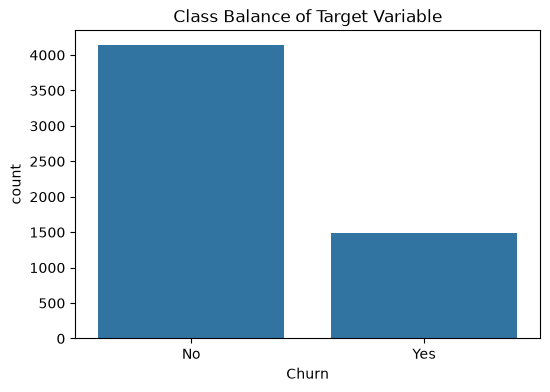

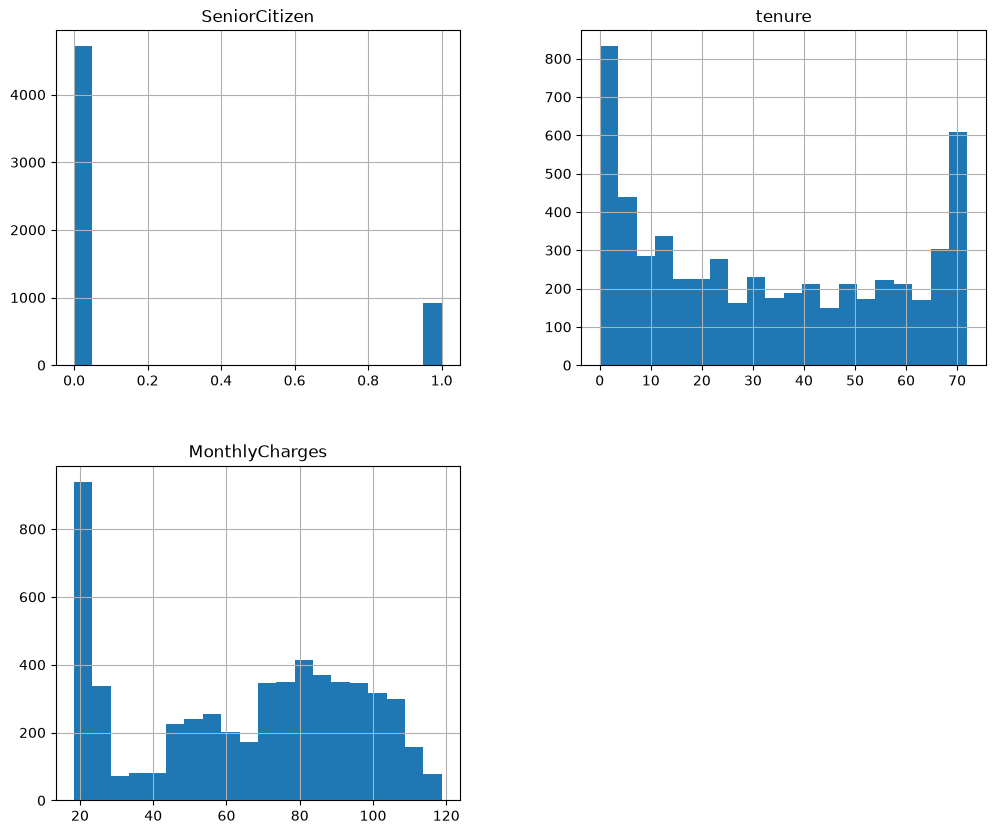

In [8]:
# visualize the historgram of the target variable and check the class balance
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=train)
plt.title('Class Balance of Target Variable')
plt.show()

# visualize histogram on data
train.hist(figsize=(12,10), bins=20)
plt.show()


#### From the histogram, we can see that the target variable is highly imbalanced, with a significant majority of customers not churning. This imbalance will need to be addressed in our modeling approach to ensure accurate predictions.

### c. Data cleaning for pre-processing for machine learning on train set
1. Drop customer ID
2. Covert 'TotalCharges' to numeric
3. Deal with rows where TotalCharges is missing 
4. Covert SeniorCitizen to categorical
5. Separate target variable(y) from features(X)


In [9]:
# 1. Drop customer ID 
train.drop(['ID'], axis=1, inplace=True)
train.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,No
1,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,No
2,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No
3,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.7,No
4,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,No


In [10]:
# 2. Covert 'TotalCharges' to numeric
train['TotalCharges'] = pd.to_numeric(train['TotalCharges'], errors='coerce')
train['TotalCharges'].info()

<class 'pandas.Series'>
RangeIndex: 5634 entries, 0 to 5633
Series name: TotalCharges
Non-Null Count  Dtype  
--------------  -----  
5626 non-null   float64
dtypes: float64(1)
memory usage: 44.1 KB


In [11]:
# 3. Check if rows where Total Charges is missing 
print(train['TotalCharges'].isna().sum())

row_with_nulls = train['TotalCharges'].isna()
print(train.loc[row_with_nulls, ['TotalCharges', 'MonthlyCharges', 'tenure', 'Churn']])

8
      TotalCharges  MonthlyCharges  tenure Churn
819            NaN           73.35       0    No
1999           NaN           20.00       0    No
2100           NaN           25.35       0    No
4710           NaN           52.55       0    No
5057           NaN           25.75       0    No
5294           NaN           56.05       0    No
5361           NaN           61.90       0    No
5608           NaN           19.85       0    No


#### There are total 8 rows where TotalCharges is missing. These rows have tenure = 0, which means these customers are new and have not been charged yet, therefore they have not churned For safety reason, we should drop these row 

In [12]:
# Drop rows where TotalCharges is missing
train = train.dropna(subset=['TotalCharges']).copy()

# Check the sape of the data after dropping rows with missing TotalCharges
print("Shape after dropping missing TotalCharges rows :", train.shape)

Shape after dropping missing TotalCharges rows : (5626, 20)


In [13]:
# 4. convert SeniorCitizen to object
train['SeniorCitizen'] = train['SeniorCitizen'].astype('object')

train['SeniorCitizen']= train['SeniorCitizen'].map({1:'Yes',0:'No'})

print(train['SeniorCitizen'].value_counts(normalize=True))


SeniorCitizen
No     0.836474
Yes    0.163526
Name: proportion, dtype: float64


In [14]:
# 5. Separate target variable(y) from features(X)
y = train['Churn']


#drop target variable from features
X = train.drop(columns=['Churn'], errors='ignore')
X.info()


<class 'pandas.DataFrame'>
Index: 5626 entries, 0 to 5633
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5626 non-null   str    
 1   SeniorCitizen     5626 non-null   str    
 2   Partner           5626 non-null   str    
 3   Dependents        5626 non-null   str    
 4   tenure            5626 non-null   int64  
 5   PhoneService      5626 non-null   str    
 6   MultipleLines     5626 non-null   str    
 7   InternetService   5626 non-null   str    
 8   OnlineSecurity    5626 non-null   str    
 9   OnlineBackup      5626 non-null   str    
 10  DeviceProtection  5626 non-null   str    
 11  TechSupport       5626 non-null   str    
 12  StreamingTV       5626 non-null   str    
 13  StreamingMovies   5626 non-null   str    
 14  Contract          5626 non-null   str    
 15  PaperlessBilling  5626 non-null   str    
 16  PaymentMethod     5626 non-null   str    
 17  MonthlyChar

In [15]:
# 6. Covert target varialbe to binary
y = y.astype(str).str.strip().str.lower() 
y.head()
y= y.map({'yes':1, 'no':0})
#print("Target variable distribution:\n", y.value_counts())



#### To comply with the leakage policy, the following Feature Engineering steps are applied to the train set only,that we will preproceeding the categorical feature by using OneHotEncoder and StandardScaler for numerical features. 

## 6. Features Engineering

### a. Indentify categorical and numerical features in train set

In [16]:
numeric_col = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

C:\Users\msdor\AppData\Local\Temp\ipykernel_4824\2624149449.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.tolist()


### b. Box plot to visualize the distribution of numerical features and identify potential outliers.

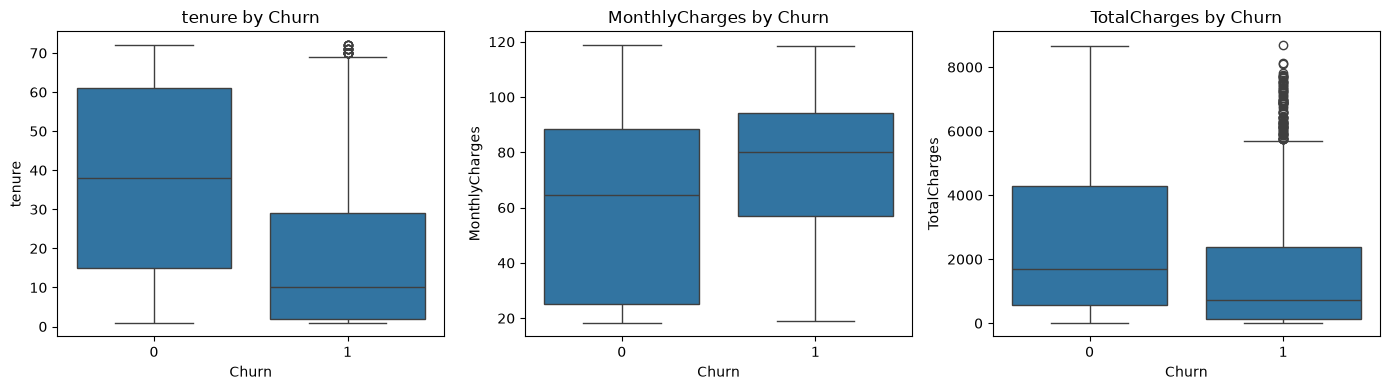

In [17]:
from matplotlib.pyplot import ylabel

fig, axes = plt.subplots(1, len(numeric_col), figsize=(14, 4))
if len(numeric_col) == 1:
    axes = [axes]

for i in range(len(numeric_col)):
    col = numeric_col[i]
    ax = axes[i]
    sns.boxplot(x=y, y=X[col], ax=ax)
    ax.set_title(f"{col} by Churn")
    ax.set_xlabel("Churn")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

#### From the box plot, it tells us that customers with shorter tenure are more likely to churn, and those with higher monthly charges are also more likely to churn.


### c. Churn rate by categorical features

In [18]:
# create a pivot table to calculate churn rate by categorical features
def churn_rate_by_category(X, y, col): 
    y_labels = y.map({1: 'Yes', 0: 'No'})
    cross_tab = pd.crosstab(X[col], y_labels, normalize='index')
    cross_tab = cross_tab.sort_values('Yes', ascending=False)
    return cross_tab

for col in categorical_cols:
    if col in X.columns:
        print(f"\n--- {col} ---")
        display(
            (churn_rate_by_category(X, y, col)*100).round(2))



--- gender ---


Churn,No,Yes
gender,,
Female,73.33,26.67
Male,73.52,26.48



--- SeniorCitizen ---


Churn,No,Yes
SeniorCitizen,,
Yes,58.91,41.09
No,76.26,23.74



--- Partner ---


...

Churn,No,Yes
Contract,,
Month-to-month,57.25,42.75
One year,88.92,11.08
Two year,97.11,2.89



--- PaperlessBilling ---


Churn,No,Yes
PaperlessBilling,,
Yes,66.18,33.82
No,83.94,16.06



--- PaymentMethod ---


Churn,No,Yes
PaymentMethod,,
Electronic check,54.26,45.74
Mailed check,80.64,19.36
Bank transfer (automatic),83.82,16.18
Credit card (automatic),85.07,14.93


#### From the churn rate by categorical feature, the high churn rate happens to those customers with the following characteristics:
1. Month to month contract 
2. Fiber optic internet service 
3. electronic check payment method 
4. No tech support and no online security

### d. Preprocessing for machine learning on train set
There are numerous ways to preprocess the data for machine learning. Ideally, we want to apply them sequentially to the training data one by one. We can use the `Pipeline` class for this task, imported from `sklearn.pipeline` module.

Let create a Pipeline that combines a SimpleImputer with median strategy, a PolynomialFeatures transformer, and a StandardScaler - all transformer for numerical features.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([    
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('cat', OneHotEncoder(handle_unknown='ignore'))])

We can use the `ColumnTransformer` class found in `sklearn.compose` module as a single transformer to handle all types of columns, categorical and numeric

In [20]:
from sklearn.compose import ColumnTransformer
full_pipeline = ColumnTransformer([
    ('num', num_pipeline, numeric_col),
    ('cat', categorical_pipeline, categorical_cols)])

## 7. Modeling 

### a. Baseline model: Logistic Regression

In [21]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocess", full_pipeline),
    ("model", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])


### b. Evaluate the baseline model and calculate the AUC score, Brier score using cross-validation

In [22]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss

baseline_model = logistic_pipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


scoring_metrics= {
    'roc_auc_score': 'roc_auc',
    'brier_score_loss': 'neg_brier_score'
}

calibrated_model = CalibratedClassifierCV(estimator=baseline_model, method='sigmoid', cv=cv)


oof_model = cross_val_predict(calibrated_model, X, y, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
print(f"Baseline model AUC score : {roc_auc_score(y, oof_model):.4f}")
print(f"Baseline model Brier score: {brier_score_loss(y, oof_model):.4f}")

print(oof_model.shape)
print(y.shape)


Baseline model AUC score : 0.8451
Baseline model Brier score: 0.1356
(5626,)
(5626,)


## 8. Two more models: Random Forest and Gradient Boosting, and evaluate their performance using cross-validation.

### a. Initial the random forest and gradient boosting model

In [23]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV

forest_pipeline = Pipeline([
    ("preprocess", full_pipeline),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced', n_estimators=400, min_samples_leaf=5,  n_jobs=-1))])

gb_pipeline = Pipeline([
    ("preprocess", full_pipeline),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE, learning_rate=0.05, n_estimators=150,max_depth=3))])

forest_pipeline.fit(X, y)
gb_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

### b. Evaluate the random forest and gradient boosting model and calculate the AUC score, Brier score using cross-validation

In [24]:
# perform cross-validation for Random Forest and Gradient Boosting models
from sklearn.metrics import roc_auc_score, brier_score_loss
models = {
    "Logistic regression": baseline_model,
    "Random forest": forest_pipeline,
    "Gradient boosting": gb_pipeline,
}

model_rows = []
oof_by_model = {}

for name, model in models.items():
    calibrated_model = CalibratedClassifierCV(
        estimator=model,
        method="sigmoid",
        cv=5
    )
# only store the positive class probabilities
    probabilities = cross_val_predict(
        calibrated_model,
        X,
        y,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Store one out-of-fold probability for every observation of positive class
    oof_by_model[name] = probabilities

    model_rows.append({
        "model": name,
        "validation_auc": roc_auc_score(y, probabilities),
        "validation_brier": brier_score_loss(y, probabilities),
    })

model_comp = (
    pd.DataFrame(model_rows)
    .sort_values(
        by="validation_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

display(model_comp)

,model,validation_auc,validation_brier
0,Gradient boosting,0.847418,0.134564
1,Random forest,0.845917,0.135477
2,Logistic regression,0.845105,0.135553


## 8. Retrain the model with removing features grouped by feature importance and evaluate the performance of the new model using cross-validation

### a. Create a feature groups

In [25]:
feature_groups = {
    "InternetServices": ["InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"],
    "ContractInfo": ["Contract", "PaperlessBilling", "PaymentMethod"],
    "BillingInfo": ["MonthlyCharges", "TotalCharges"],
    "Demographics": ["gender", "SeniorCitizen", "Partner", "Dependents"],
    "PhoneServices": ["PhoneService", "MultipleLines"],
    "Tenure": ["tenure"],
}

### b. Retrain the model with removing grouped feature and create the ablation results.

In [26]:
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss

models = {
    "Logistic regression": logistic_pipeline,
    "Random forest": forest_pipeline,
    "Gradient boosting": gb_pipeline,
}

ablation_results = []

for group_name, features_to_drop in feature_groups.items():
    X_group = X.drop(
        columns=features_to_drop,
        errors="ignore"
    )

    numeric_group = X_group.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_group = X_group.select_dtypes(
        exclude=["number"]
    ).columns.tolist()

    numeric_transformer_group = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer_group = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    group_preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_transformer_group,
            numeric_group
        ),
        (
            "categorical",
            categorical_transformer_group,
            categorical_group
        ),
    ])

    for model_name, original_pipeline in models.items():
        estimator = clone(original_pipeline.steps[-1][1])

        group_pipeline = Pipeline([
            ("preprocessor", group_preprocessor),
            ("model", estimator),
        ])

        calibrated_model = CalibratedClassifierCV(
            estimator=group_pipeline,
            method="sigmoid",
            cv=cv,
        )

        probabilities = cross_val_predict(
            calibrated_model,
            X_group,
            y,
            cv=cv,
            method="predict_proba",
            n_jobs=-1,
        )[:, 1]

        ablation_results.append({
            "removed_group": group_name,
            "model": model_name,
            "auc": roc_auc_score(y, probabilities),
            "brier_score": brier_score_loss(y, probabilities),
        })

ablation_results = pd.DataFrame(ablation_results)
display(ablation_results)

,removed_group,model,auc,brier_score
0,InternetServices,Logistic regression,0.838168,0.138609
1,InternetServices,Random forest,0.837020,0.139160
2,InternetServices,Gradient boosting,0.841588,0.136699
3,ContractInfo,Logistic regression,0.834998,0.138752
4,ContractInfo,Random forest,0.832652,0.139288
5,ContractInfo,Gradient boosting,0.837891,0.137380
6,BillingInfo,Logistic regression,0.843785,0.135959
7,BillingInfo,Random forest,0.844039,0.136353
8,BillingInfo,Gradient boosting,0.847811,0.134046
9,Demographics,Logistic regression,0.845184,0.135534
